# Explainability: Best Models for each Configuration

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap
shap.initjs()

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split

/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df_train = pd.read_csv('/Users/laviniarotellini/Desktop/Laurea/Tesi/Costruzione e Analisi DF/5. Classification/df_train.csv')
df_test = pd.read_csv('/Users/laviniarotellini/Desktop/Laurea/Tesi/Costruzione e Analisi DF/5. Classification/df_test.csv')

In [3]:
n_classes = 3

In [4]:
lab_encoder = joblib.load('/Users/laviniarotellini/Desktop/Laurea/Tesi/Costruzione e Analisi DF/3. Data Understanding and Prep/label_encoder.pkl')

1. 

In [5]:
cols_to_drop = df_train.filter(regex=r"2020").columns.tolist()
df_train = df_train.drop(cols_to_drop, axis = 1)
df_test = df_test.drop(cols_to_drop, axis = 1)

In [6]:
y_test = df_test['target']
x_test = df_test.drop('target', axis=1)

In [7]:
y = df_train['target']
X = df_train.drop('target', axis = 1)

In [8]:
x_train, x_val, y_train, y_val = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)

In [9]:
columns_to_scale = df_train.filter(regex=r"\d{4}").columns.tolist()
scaler = StandardScaler()

x_train[columns_to_scale] = scaler.fit_transform(x_train[columns_to_scale])
x_val[columns_to_scale] = scaler.transform(x_val[columns_to_scale])
x_test[columns_to_scale] = scaler.transform(x_test[columns_to_scale])

In [10]:
x_train.shape

(344, 292)

2. Caricamento dei modelli migliori con e senza city

In [11]:
model_city = joblib.load('/Users/laviniarotellini/Library/CloudStorage/OneDrive-UniversityofPisa(2)/models-tesi/Modelli a tre anni con city/log_reg_tre_city.pkl')
#model_no_city = joblib.load('/Users/laviniarotellini/Library/CloudStorage/OneDrive-UniversityofPisa(2)/models-tesi/Modelli a tre anni senza city/log_reg_tre_nocity.pkl')

3. SHAP

3.1 City

In [12]:
x_train = x_train.astype(np.float64)
x_val = x_val.astype(np.float64)
x_test = x_test.astype(np.float64)

In [13]:
explainer_city = shap.LinearExplainer(model_city, x_train)
shap_values_city = explainer_city(x_train)

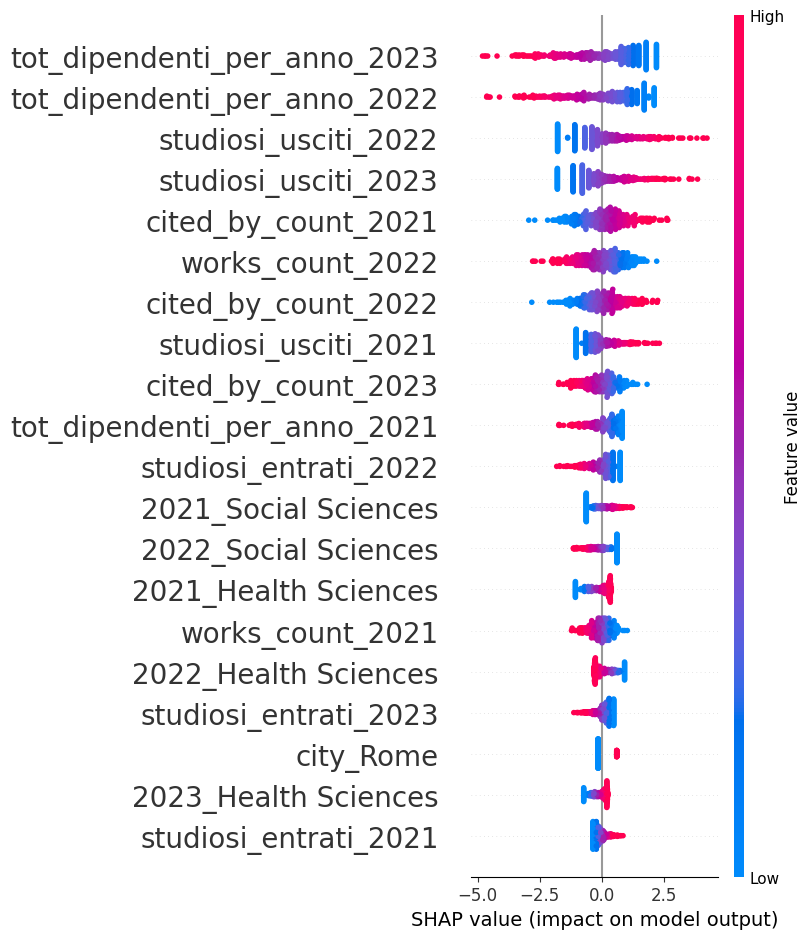

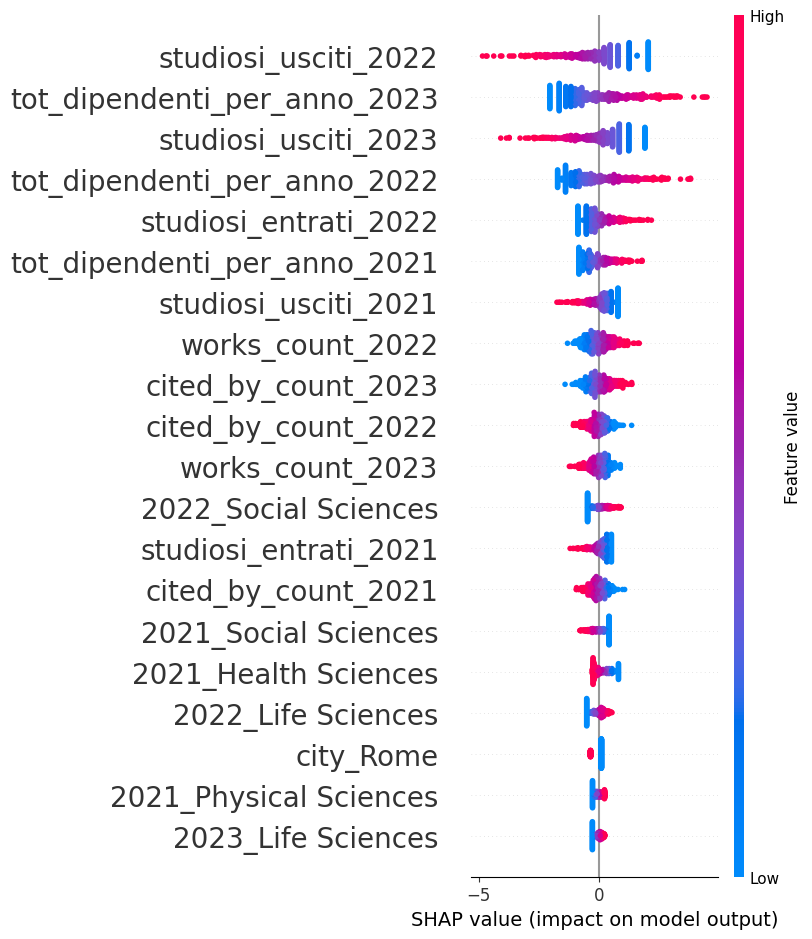

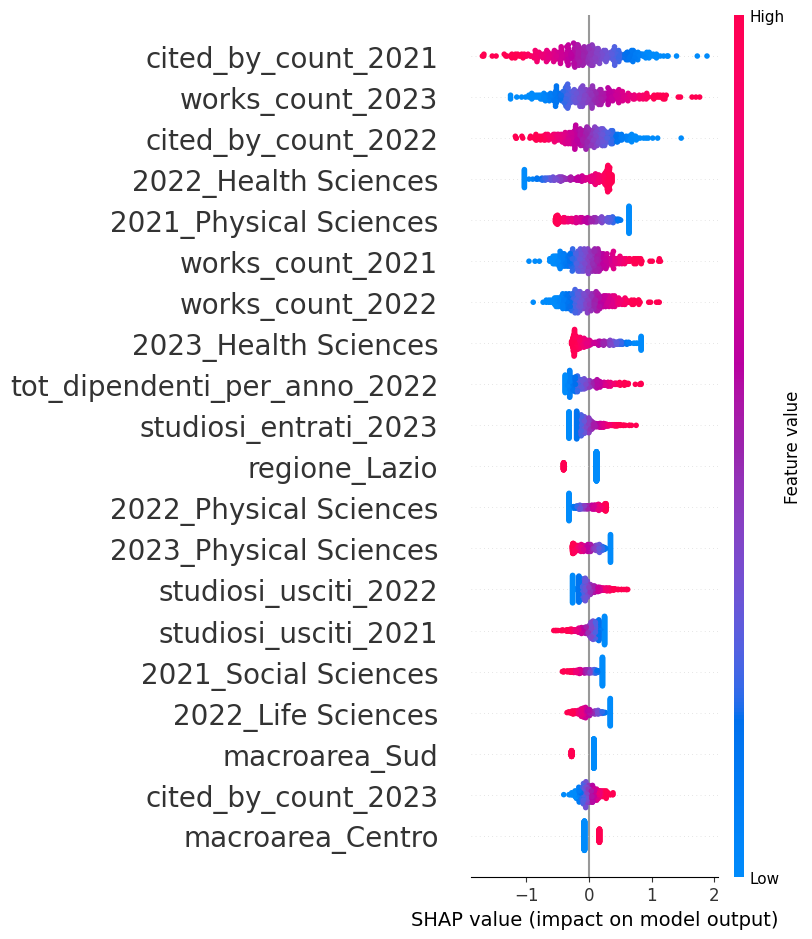

In [14]:
import os
import matplotlib.pyplot as plt

save_dir = "/Users/laviniarotellini/Downloads/Template_tesi_di_laurea_in_Informatica_Umanistica__Università_di_Pisa_/immagini/xai"

# opzionale: crea la directory se non esiste
os.makedirs(save_dir, exist_ok=True)

for i in range(n_classes):
    plt.figure()
    shap.summary_plot(
        shap_values_city[:, :, i],
        x_train,
        show=False  # ← importante: non mostrare subito
    )
    
    ax = plt.gca()
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=20)  # label features (asse Y)
    ax.set_xlabel(ax.get_xlabel(), fontsize=14)             # label asse X
    ax.tick_params(axis='x', labelsize=12)                  # tick asse X
    
    plt.tight_layout()
    plt.savefig(f"classe_{i}.png", dpi=150, bbox_inches='tight')
    plt.show()

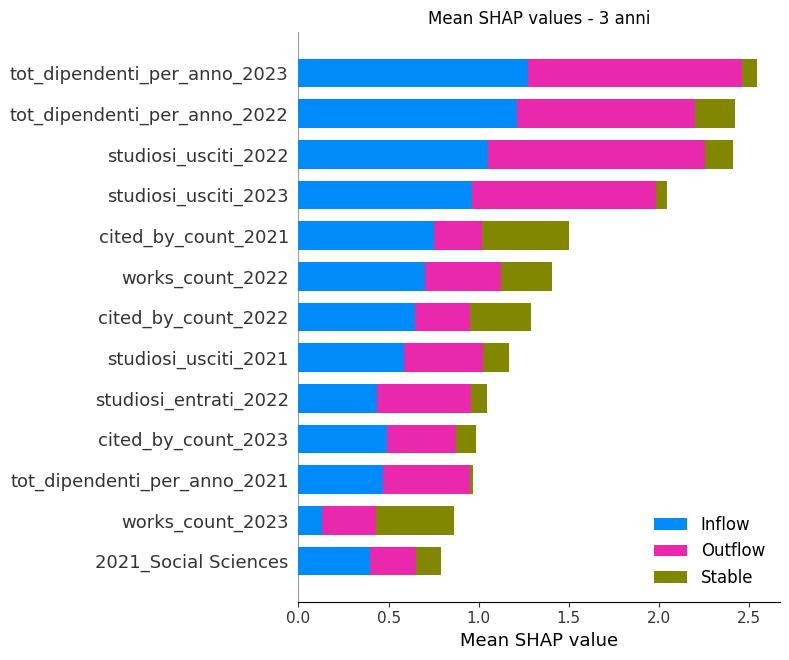

In [15]:
shap.summary_plot(
    shap_values_city, 
    x_train, 
    plot_type="bar", 
    max_display=13,
    show=False, 
    class_names = ['Inflow', 'Outflow', 'Stable']
)

# ax = plt.gca()

# # Recupera i handle esistenti e sostituisci solo le label
# handles, _ = ax.get_legend_handles_labels()
# ax.legend(handles, ['Inflow', 'Outflow', 'Stable'], fontsize=11)

plt.xlabel("Mean SHAP value")
plt.title("Mean SHAP values - 3 anni")
plt.tight_layout()
plt.show()

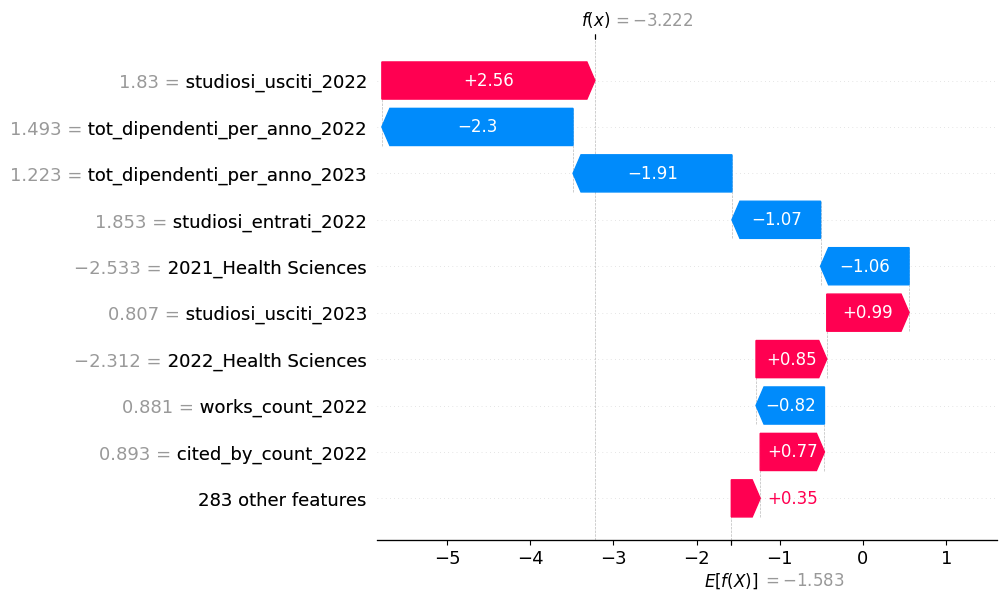

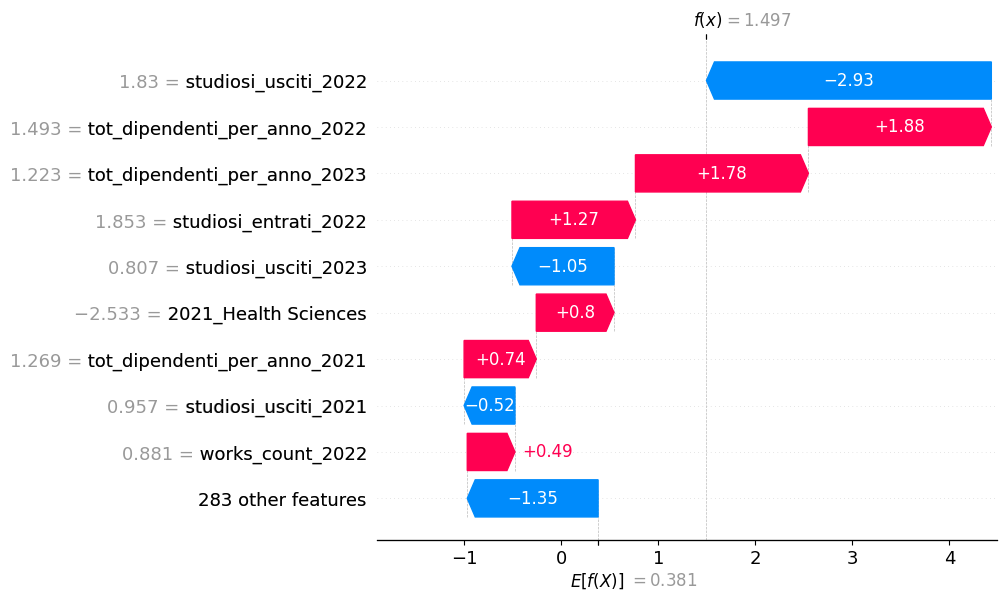

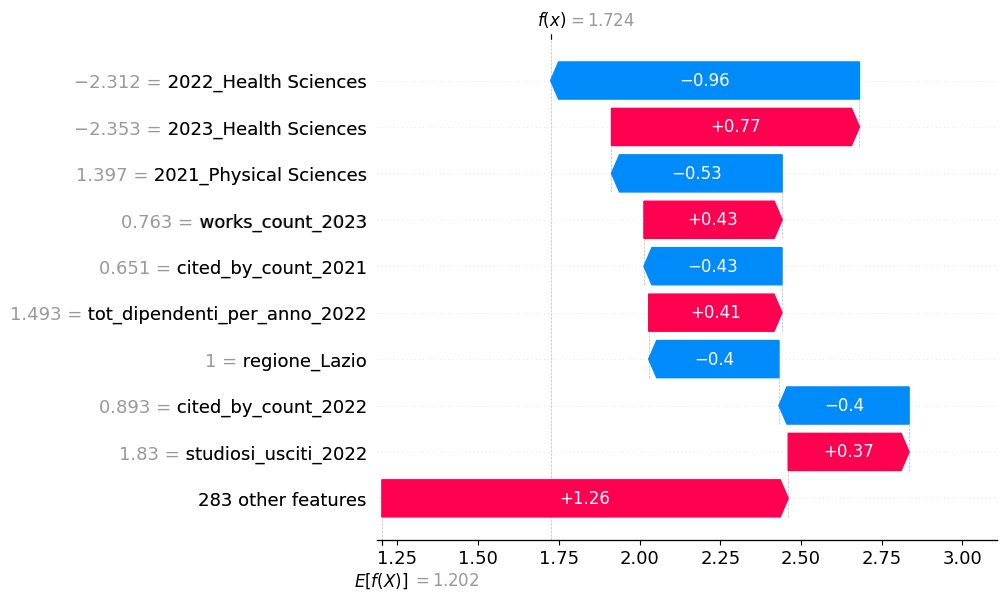

In [16]:
for i in range(n_classes):
    shap.waterfall_plot(shap_values_city[0, :, i])

4.1 Ri Allenamento del modello

In [17]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [19]:
# Estrai i valori dall'oggetto Explanation
shap_vals = (
    shap_values_city.values
    if hasattr(shap_values_city, "values")
    else np.stack(shap_values_city, axis=2)
)

# Se ha 3 dimensioni (multiclass), fai mean su samples e classes
shap_importance_city = np.mean(np.abs(shap_vals), axis=(0, 2))

In [20]:
# creazione dataframe
feature_importance = pd.DataFrame({
    "feature": X.columns,
    "mean_abs_shap": shap_importance_city
})

# ordinamento
feature_importance = feature_importance.sort_values(
    by="mean_abs_shap",
    ascending=False
)

In [21]:
feature_importance[10:30]

,feature,mean_abs_shap
6,tot_dipendenti_per_anno_2021,0.322833
0,works_count_2023,0.287318
17,2021_Social Sciences,0.262830
21,2022_Social Sciences,0.249858
15,2021_Health Sciences,0.222208
19,2022_Health Sciences,0.217470
18,2021_Physical Sciences,0.211447
4,works_count_2021,0.207178
8,studiosi_entrati_2021,0.194595
14,studiosi_entrati_2023,0.180831


In [22]:
log_reg_params = [
    {
        'solver': ['lbfgs', 'newton-cg'],
        'C': [0.01, 0.1, 1],
        'class_weight': ['balanced'],
        'max_iter': [300, 1000],
        'penalty': ['l2']
    },
    {
        'solver': ['sag', 'saga'],
        'C': [0.01, 0.1, 1],
        'class_weight': ['balanced'],
        'max_iter': [1000, 5000],
        'penalty': ['l2']
    }
]


grid_log_reg = GridSearchCV(LogisticRegression(),
                            log_reg_params, 
                            cv = cv, 
                            scoring = 'f1_macro',
                            verbose=1,
                            )

validation_dict = {}

In [23]:
def different_idx(shap_values, results_dict, X_train_df, X_val_df, y_train, y_val):
    
    shap_vals = (
        shap_values.values
        if hasattr(shap_values, "values")
        else np.stack(shap_values, axis=2)
    )
    shap_importance = np.mean(np.abs(shap_vals), axis=(0, 2))
    
    best_f1       = -1
    best_model    = None
    best_X_train  = None
    best_X_val    = None
    best_features = None
    
    for i in range(40, 52):
        top_idx      = np.argsort(shap_importance)[::-1][:i]
        top_features = X_train_df.columns[top_idx]
        
        X_train_top = X_train_df[top_features]
        X_val_top   = X_val_df[top_features]
        
        grid_log_reg.fit(X_train_top, y_train)
        lr = grid_log_reg.best_estimator_
        
        y_pred = lr.predict(X_val_top)
        acc = accuracy_score(y_val, y_pred)
        f1  = f1_score(y_val, y_pred, average="macro")
        
        results_dict[i] = {
            'n_features' : i,
            'accuracy'   : round(acc, 4),
            'f1'         : round(f1, 4),
            'best_params': grid_log_reg.best_params_
        }
        
        if f1 > best_f1:
            best_f1       = f1
            best_model    = lr
            best_X_train  = X_train_top
            best_X_val    = X_val_top
            best_features = top_features
    
    return results_dict, best_model, best_X_train, best_X_val, best_features

results = {}
# Chiamata
results, lr_model, new_x_train, new_x_val, top_features = different_idx(
    shap_values_city, results,
    X_train_df=x_train, X_val_df=x_val,
    y_train=y_train, y_val=y_val
)

# Ora new_x_val ha esattamente le features su cui lr_model è stato fittato
y_pred_city = lr_model.predict(new_x_val)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 

Fitting 5 folds for each of 24 candidates, totalling 120 fits


/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 

Fitting 5 folds for each of 24 candidates, totalling 120 fits


/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 

... (14 outputs left out)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 

Fitting 5 folds for each of 24 candidates, totalling 120 fits


/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 

In [24]:
df_results = pd.DataFrame(results).T.reset_index(drop=True)
df_results = df_results.sort_values(by='f1', ascending=False)

In [25]:
df_results

,n_features,accuracy,f1,best_params
6,46,0.6304,0.5812,"{'C': 0.1, 'class_weight': 'balanced', 'max_it..."
3,43,0.6348,0.5702,"{'C': 1, 'class_weight': 'balanced', 'max_iter..."
1,41,0.6391,0.5664,"{'C': 1, 'class_weight': 'balanced', 'max_iter..."
9,49,0.613,0.5664,"{'C': 0.1, 'class_weight': 'balanced', 'max_it..."
2,42,0.6348,0.5636,"{'C': 1, 'class_weight': 'balanced', 'max_iter..."
5,45,0.6304,0.5625,"{'C': 1, 'class_weight': 'balanced', 'max_iter..."
4,44,0.6261,0.5581,"{'C': 1, 'class_weight': 'balanced', 'max_iter..."
0,40,0.6348,0.5545,"{'C': 1, 'class_weight': 'balanced', 'max_iter..."
10,50,0.5957,0.5414,"{'C': 1, 'class_weight': 'balanced', 'max_iter..."
8,48,0.6043,0.5299,"{'C': 1, 'class_weight': 'balanced', 'max_iter..."


In [26]:
top_features

Index(['tot_dipendenti_per_anno_2023', 'tot_dipendenti_per_anno_2022',
       'studiosi_usciti_2022', 'studiosi_usciti_2023', 'cited_by_count_2021',
       'works_count_2022', 'cited_by_count_2022', 'studiosi_usciti_2021',
       'studiosi_entrati_2022', 'cited_by_count_2023',
       'tot_dipendenti_per_anno_2021', 'works_count_2023',
       '2021_Social Sciences', '2022_Social Sciences', '2021_Health Sciences',
       '2022_Health Sciences', '2021_Physical Sciences', 'works_count_2021',
       'studiosi_entrati_2021', 'studiosi_entrati_2023',
       '2023_Health Sciences', 'city_Rome', '2022_Life Sciences',
       'regione_Lazio', '2023_Life Sciences', '2022_Physical Sciences',
       '2023_Physical Sciences', '2023_Social Sciences', 'macroarea_Sud',
       'type_company', 'macroarea_Centro', 'type_education', 'city_Milan',
       '2021_Life Sciences', 'type_facility', 'regione_Emilia-Romagna',
       'regione_Veneto', 'regione_Sicily', 'macroarea_Isole',
       'regione_Piedmont', 'r

In [27]:
print('Classification Report per Logistic Regression')
print(classification_report(y_val, y_pred_city))
print(f'Accuracy della Logistic Regression: {accuracy_score(y_val, y_pred_city)}')
print(f'F1 Score della Logistic Regression: {f1_score(y_val, y_pred_city, average="weighted")}')

Classification Report per Logistic Regression
              precision    recall  f1-score   support

           0       0.39      0.71      0.51        21
           1       0.41      0.73      0.53        48
           2       0.89      0.59      0.71       161

    accuracy                           0.63       230
   macro avg       0.56      0.68      0.58       230
weighted avg       0.74      0.63      0.65       230

Accuracy della Logistic Regression: 0.6304347826086957
F1 Score della Logistic Regression: 0.6525344132226429


In [28]:
# Unisco train e validation
X_full = pd.concat([x_train, x_val])
y_full = pd.concat([y_train, y_val])

X_full_top = X_full[top_features]

# Rifitto il modello con i migliori parametri trovati
final_model = LogisticRegression(**lr_model.get_params())
final_model.fit(X_full_top, y_full)

/Users/laviniarotellini/Desktop/Laurea/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

5.1 Evaluation

In [29]:
y_test_pred = final_model.predict(x_test[top_features])
    
test_accuracy = accuracy_score(y_test, y_test_pred)
test_f1_weighted = f1_score(y_test, y_test_pred, average='weighted')
test_f1_macro = f1_score(y_test, y_test_pred, average='macro')

In [30]:
print(classification_report(y_test, y_test_pred, 
                                  target_names=lab_encoder.classes_))
print('*' * 50)

              precision    recall  f1-score   support

      inflow       0.27      0.68      0.39        38
     outflow       0.45      0.52      0.48        90
      stable       0.86      0.62      0.72       256

    accuracy                           0.60       384
   macro avg       0.53      0.61      0.53       384
weighted avg       0.70      0.60      0.63       384

**************************************************


3.2 Senza city

In [31]:
df_train_no_city = df_train.loc[:, ~df_train.columns.str.contains(r'city')]
df_test_no_city = df_test.loc[:, ~df_test.columns.str.contains(r'city')]

In [32]:
y_test_no_city = df_test_no_city['target']
x_test_no_city = df_test_no_city.drop('target', axis=1)

In [33]:
y_nocity = df_train_no_city['target']
X_nocity = df_train_no_city.drop('target', axis = 1)

In [34]:
x_train, x_val, y_train, y_val = train_test_split(X_nocity, y_nocity, test_size=0.4, random_state=42, stratify=y_nocity)

In [35]:
columns_to_scale = df_train_no_city.filter(regex=r"\d{4}").columns.tolist()
scaler = StandardScaler()

x_train[columns_to_scale] = scaler.fit_transform(x_train[columns_to_scale])
x_val[columns_to_scale] = scaler.transform(x_val[columns_to_scale])
df_test_no_city[columns_to_scale] = scaler.transform(df_test_no_city[columns_to_scale])

/var/folders/32/wr6jfczj32q0c3fcn7fkrtvr0000gn/T/ipykernel_1191/4128192901.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_no_city[columns_to_scale] = scaler.transform(df_test_no_city[columns_to_scale])


In [36]:
explainer_nocity = shap.LinearExplainer(model_no_city, x_train)
shap_values_nocity = explainer_nocity(x_val)

NameError: name 'model_no_city' is not defined


--- Classe 0 ---


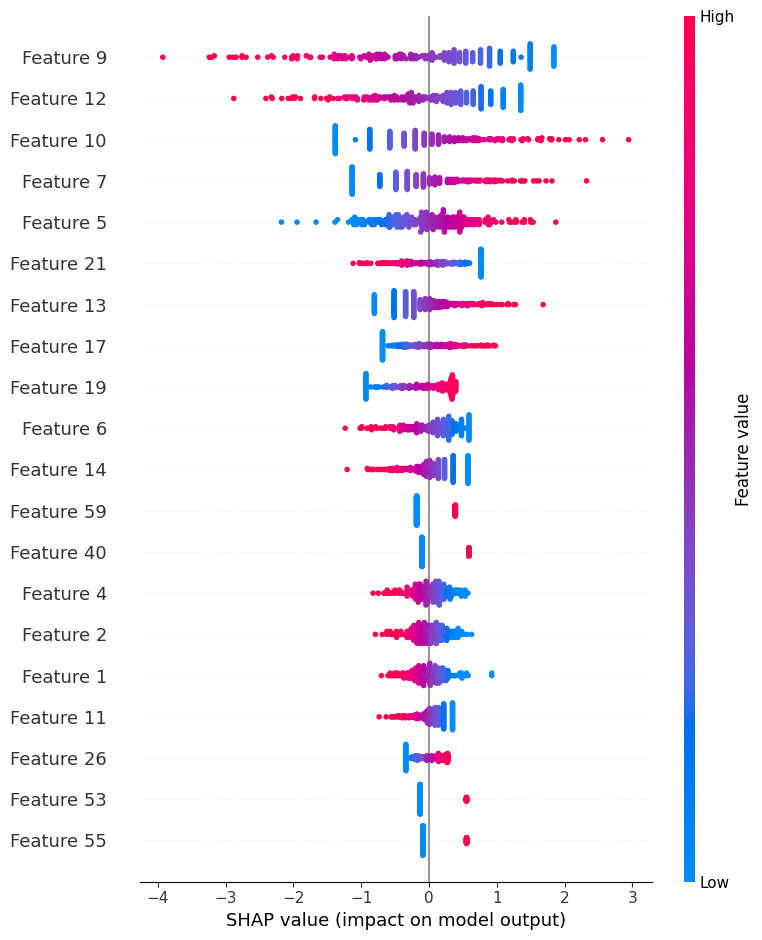


--- Classe 1 ---


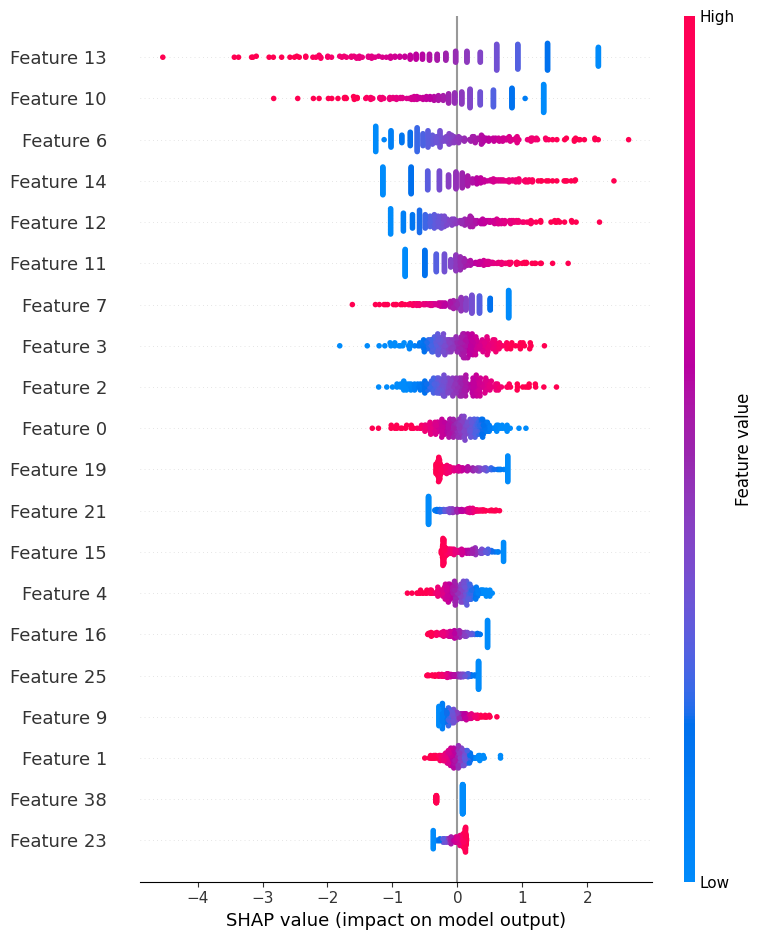


--- Classe 2 ---


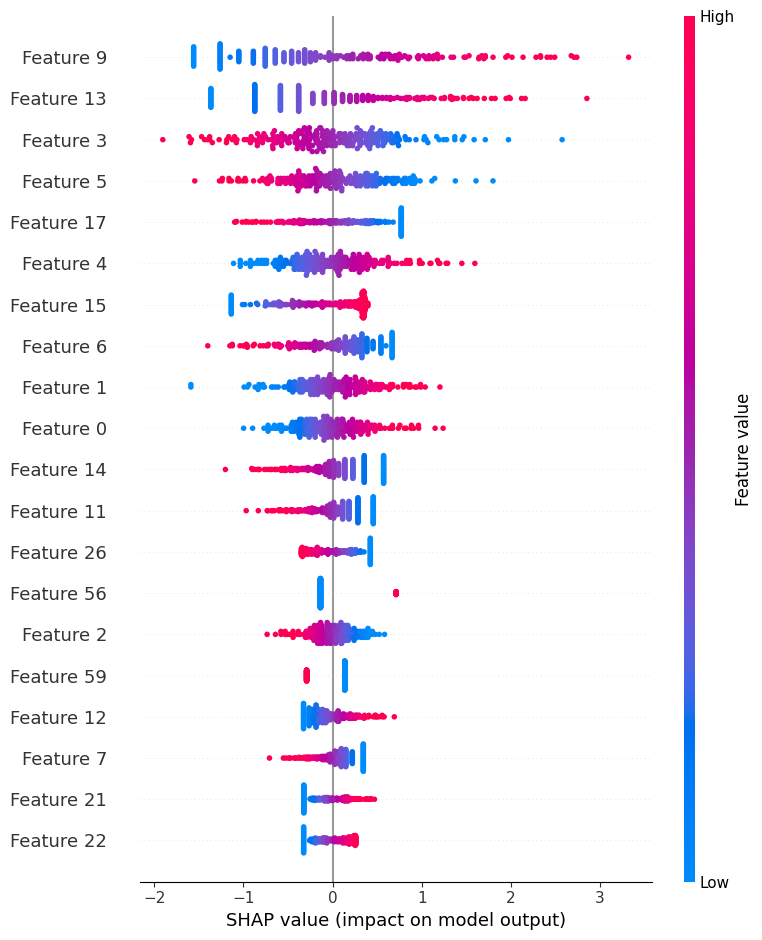

In [ ]:
shap_values_float_nocity = shap_values_nocity.values.astype(np.float64)
x_test_float_nocity = np.array(x_val, dtype=np.float64)

for i in range(n_classes):
    print(f"\n--- Classe {i} ---")
    shap.summary_plot(shap_values_float_nocity[:, :, i], x_test_float_nocity, show=True)

In [ ]:
shap.summary_plot(shap_values_city, x_train, plot_type="bar", max_display=13, show= False, class_names = ['Inflow', 'Outflow', 'Stable'] )
plt.xlabel("Mean SHAP value")
plt.title("Mean SHAP values - 3 anni")
plt.tight_layout()
plt.show()

NameError: name 'shap' is not defined

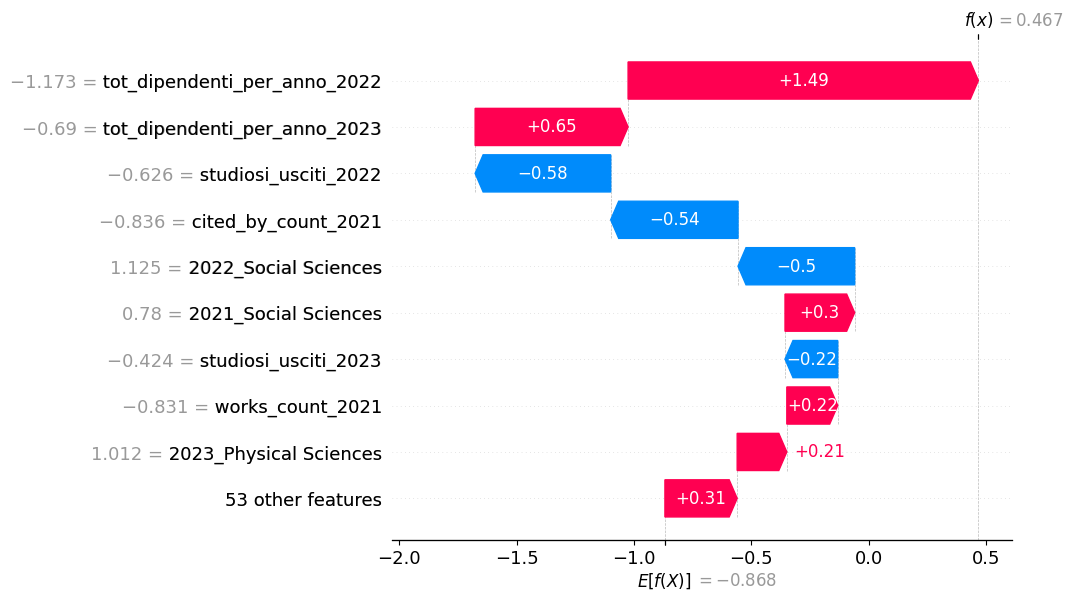

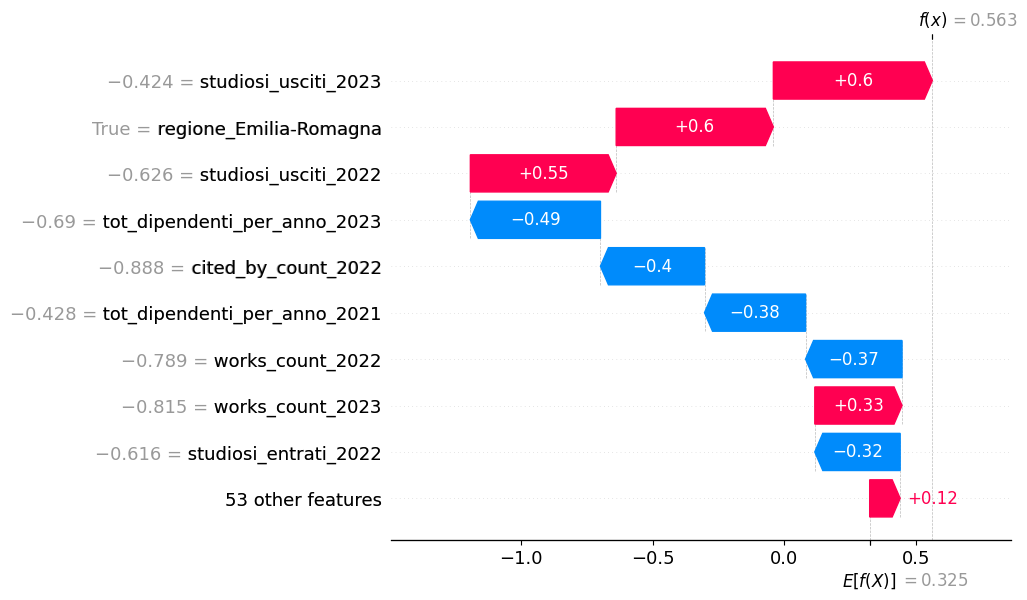

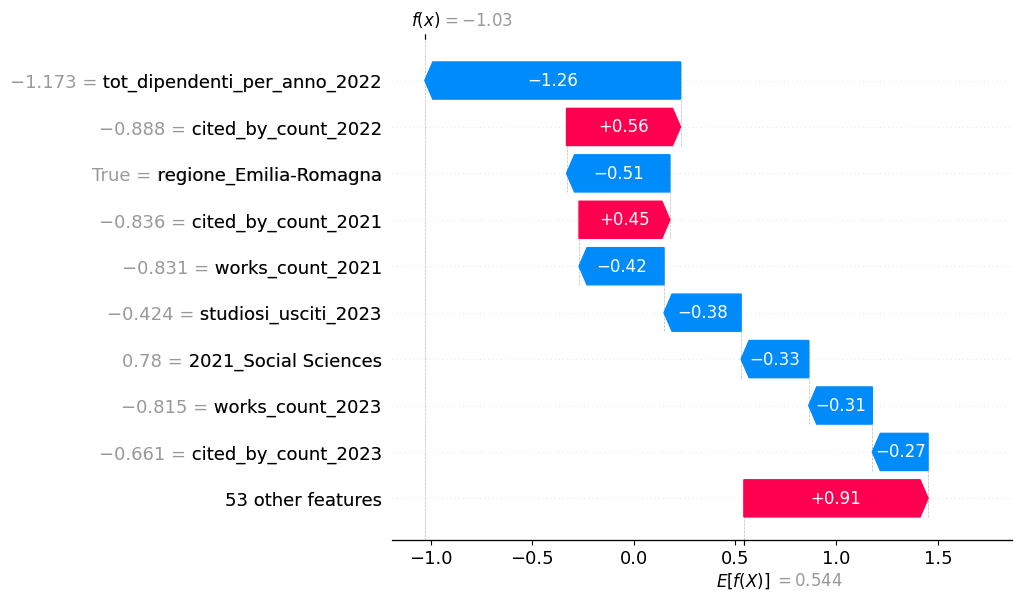

In [ ]:
for i in range(n_classes):
    shap.waterfall_plot(shap_values_nocity[0, :, i])

4.2 Ri allenamento modello no city

In [ ]:
# Estrai i valori dall'oggetto Explanation
shap_vals = shap_values_nocity.values  # shape: (n_samples, n_features) o (n_samples, n_features, n_classes)

# Se ha 3 dimensioni (multiclass), fai mean su samples e classes
if shap_vals.ndim == 3:
    shap_importance_nocity = np.abs(shap_vals).mean(axis=0).mean(axis=1)
else:
    shap_importance_nocity = np.abs(shap_vals).mean(axis=0)

top_20_idx_nocity = np.argsort(shap_importance_nocity)[::-1][:20]
top20_features_nocity = np.array(x_val.columns)[top_20_idx_nocity]
print(top20_features_nocity.tolist())

['studiosi_usciti_2023', 'tot_dipendenti_per_anno_2022', 'tot_dipendenti_per_anno_2023', 'studiosi_usciti_2022', 'tot_dipendenti_per_anno_2021', 'studiosi_entrati_2023', 'studiosi_usciti_2021', 'cited_by_count_2022', 'cited_by_count_2021', 'studiosi_entrati_2022', '2022_Social Sciences', '2021_Social Sciences', 'works_count_2021', 'works_count_2022', '2021_Health Sciences', '2022_Health Sciences', 'cited_by_count_2023', 'works_count_2023', 'type_healthcare', '2023_Physical Sciences']


In [ ]:
new_x_train = x_train[top20_features_nocity]
new_x_val = x_val[top20_features_nocity]

In [ ]:
grid_log_reg.fit(new_x_train, y_train)
print(grid_log_reg.best_params_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


/Users/laviniarotellini/Desktop/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was depreca

{'C': 1, 'class_weight': 'balanced', 'max_iter': 300, 'penalty': 'l2', 'solver': 'lbfgs'}


/Users/laviniarotellini/Desktop/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/laviniarotellini/Desktop/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was depreca

In [ ]:
lr_no_city = LogisticRegression(**grid_log_reg.best_params_, random_state=42)
lr_no_city.fit(new_x_train, y_train)

/Users/laviniarotellini/Desktop/Tesi/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclas

In [ ]:
y_pred_no_city = lr_no_city.predict(new_x_val)
print('Classification Report per Logistic Regression')
print(classification_report(y_val, y_pred_no_city))
print(f'Accuracy della Logistic Regression: {accuracy_score(y_val, y_pred_no_city)}')
print(f'F1 Score della Logistic Regression: {f1_score(y_val, y_pred_no_city, average="weighted")}')

Classification Report per Logistic Regression
              precision    recall  f1-score   support

           0       0.25      0.56      0.34        25
           1       0.52      0.58      0.55        69
           2       0.73      0.51      0.60       136

    accuracy                           0.54       230
   macro avg       0.50      0.55      0.50       230
weighted avg       0.61      0.54      0.56       230

Accuracy della Logistic Regression: 0.5391304347826087
F1 Score della Logistic Regression: 0.5583207393964227


5.2 Evaluation

In [ ]:
y_pred_no_city = lr_no_city.predict(x_test_no_city[top20_features_nocity])
    
test_accuracy = accuracy_score(y_test_no_city, y_pred_no_city)
test_f1_weighted = f1_score(y_test_no_city, y_pred_no_city, average='weighted')
test_f1_macro = f1_score(y_test_no_city, y_pred_no_city, average='macro')
    

print(classification_report(y_test_no_city, y_pred_no_city, 
                                  target_names=lab_encoder.classes_))
print('*' * 50)

              precision    recall  f1-score   support

      inflow       0.33      0.65      0.44        43
     outflow       0.45      0.50      0.47       115
      stable       0.72      0.55      0.62       226

    accuracy                           0.54       384
   macro avg       0.50      0.57      0.51       384
weighted avg       0.59      0.54      0.56       384

**************************************************
